# Part 1 — Probability Distributions: Expectation–Maximization (EM) Algorithm for a Mixture of Two Gaussian Distributions

**Question:** Galton's height data contains two populations, *Children* and *Fathers*. If we hide the labels, can the Expectation–Maximization algorithm recover the two groups, and what is the probability that a new height belongs to each group?

**What this notebook contains**
1. Load and prepare the data
2. The model and its parameters
3. EM built from scratch (initialization → E-step → M-step → stopping rule)
4. The required tracking table
5. Should we just split at the global mean? (evidence)
6. What EM actually found (checked with the hidden labels)
7. Live demo — posterior probabilities for a test height

*From scratch* = NumPy is used only for arrays and arithmetic; no scikit-learn, no SciPy distributions.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = os.path.join("..", "data", "GaltonFamilies.csv")
IMAGES_DIR = os.path.join("..", "images")
LABELS = ("Children", "Fathers")   # component 1 (shorter), component 2 (taller)
TOLERANCE = 1e-6                   # stop when log-likelihood improves by less than this
MAX_ITERATIONS = 1000
os.makedirs(IMAGES_DIR, exist_ok=True)


def save_and_show(filename):
    # Save the current figure to images/ (used in the README) and display it here.
    plt.tight_layout()
    plt.savefig(os.path.join(IMAGES_DIR, filename), dpi=120)
    plt.show()

## 1. Data

Dataset: Kaggle — *Parents' Heights vs Children's Heights (Galton data)*: 934 rows (one per child), 205 families, heights in inches. We chose **Fathers and Children**.

* **Children:** all 934 values of `childHeight`.
* **Fathers:** 205 values of `father`, **one per family**. In the file a father is repeated on the row of every one of his children (up to 15 times), so we drop duplicates — one man, one height.

The labels (daughter / son / father) are kept aside and **never given to EM**. We only use them at the end to check the result.

In [2]:
def load_heights(path=DATA_PATH):
    # Return (heights, hidden_groups). hidden_groups is used only for checking, never by EM.
    df = pd.read_csv(path)
    fathers = df.drop_duplicates("family")
    heights = np.concatenate([df["childHeight"].to_numpy(float), fathers["father"].to_numpy(float)])
    child_groups = np.where(df["gender"] == "male", "son", "daughter")
    groups = np.concatenate([child_groups, np.full(len(fathers), "father")])
    return heights, groups


heights, groups = load_heights()
print("Rows in file: 934 children,", len(np.unique(pd.read_csv(DATA_PATH)['family'])), "families")
print("Heights given to EM:", len(heights), "(934 children + 205 fathers)")
print(f"Global mean = {heights.mean():.4f} in, min = {heights.min()}, max = {heights.max()}")

Rows in file: 934 children, 205 families
Heights given to EM: 1139 (934 children + 205 fathers)
Global mean = 67.2085 in, min = 56.0, max = 79.0


## 2. The model

Every height $x$ is assumed to come from one of two bell curves (Gaussian distributions):

$$p(x)=\pi_1\,\mathcal N(x\mid\mu_1,\sigma_1^2)+\pi_2\,\mathcal N(x\mid\mu_2,\sigma_2^2),\qquad
\mathcal N(x\mid\mu,\sigma^2)=\frac{1}{\sqrt{2\pi\sigma^2}}\,e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$

| Parameter | Meaning |
|---|---|
| $\mu_1,\mu_2$ | means (centre of each bell curve) |
| $\sigma_1^2,\sigma_2^2$ | variances (width of each curve) |
| $\pi_1,\pi_2$ | mixing coefficients: share of the data from each group, $\pi_1+\pi_2=1$ |

**Log-likelihood** — how well the current parameters explain all $n=1139$ heights (higher is better):
$$\log L=\sum_{i=1}^{n}\log\big(\pi_1\mathcal N(x_i\mid\mu_1,\sigma_1^2)+\pi_2\mathcal N(x_i\mid\mu_2,\sigma_2^2)\big)$$

In [3]:
def gaussian_pdf(x, mean, variance):
    # N(x | mean, variance)
    return np.exp(-((x - mean) ** 2) / (2.0 * variance)) / np.sqrt(2.0 * np.pi * variance)


def weighted_densities(x, params):
    # Column k holds pi_k * N(x_i | mu_k, var_k); shape (n_points, 2)
    return np.column_stack([params["pi"][k] * gaussian_pdf(x, params["mu"][k], params["var"][k])
                            for k in range(2)])


def log_likelihood(x, params):
    return float(np.sum(np.log(weighted_densities(x, params).sum(axis=1))))

## 3. EM from scratch

**Initialization (iteration 0).** We deliberately start from the *naive* method: cut at the global mean, take each pile's mean, variance and share. The tracking table then shows exactly how EM corrects that naive answer.

**E-step (Expectation).** For every height, Bayes' theorem gives the *responsibility* — the probability that the height belongs to group $k$:
$$r_{ik}=\frac{\pi_k\,\mathcal N(x_i\mid\mu_k,\sigma_k^2)}{\pi_1\mathcal N(x_i\mid\mu_1,\sigma_1^2)+\pi_2\mathcal N(x_i\mid\mu_2,\sigma_2^2)}$$
This is a **soft assignment**: each height is shared between both groups and its two responsibilities add up to 1.

**M-step (Maximization).** Re-estimate every parameter, using the responsibilities as weights:
$$N_k=\sum_i r_{ik},\qquad \mu_k=\frac{\sum_i r_{ik}x_i}{N_k},\qquad \sigma_k^2=\frac{\sum_i r_{ik}(x_i-\mu_k)^2}{N_k},\qquad \pi_k=\frac{N_k}{n}$$

**Stopping rule.** Repeat E and M until the log-likelihood improves by less than $10^{-6}$ (it has converged).

In [4]:
def global_mean_split(x):
    # The naive method: cut at the global mean.
    cut = x.mean()
    return cut, x[x < cut], x[x >= cut]


def initialize(x):
    _, low, high = global_mean_split(x)
    return {"mu": np.array([low.mean(), high.mean()]),
            "var": np.array([low.var(), high.var()]),
            "pi": np.array([len(low), len(high)]) / len(x)}


def e_step(x, params):
    weighted = weighted_densities(x, params)
    return weighted / weighted.sum(axis=1, keepdims=True)      # responsibilities, rows sum to 1


def m_step(x, responsibilities):
    n_k = responsibilities.sum(axis=0)
    mu = (responsibilities * x[:, None]).sum(axis=0) / n_k
    var = (responsibilities * (x[:, None] - mu) ** 2).sum(axis=0) / n_k
    return {"mu": mu, "var": var, "pi": n_k / len(x)}


def snapshot(iteration, x, params):
    # One row of the tracking table.
    return {"Iteration": iteration,
            "μ1 (Children)": params["mu"][0], "μ2 (Fathers)": params["mu"][1],
            "σ1²": params["var"][0], "σ2²": params["var"][1],
            "π1": params["pi"][0], "π2": params["pi"][1],
            "Log-Likelihood": log_likelihood(x, params)}


def run_em(x, tol=TOLERANCE, max_iter=MAX_ITERATIONS):
    params = initialize(x)
    history = [snapshot(0, x, params)]
    for iteration in range(1, max_iter + 1):
        responsibilities = e_step(x, params)          # E-step
        params = m_step(x, responsibilities)          # M-step
        history.append(snapshot(iteration, x, params))
        if abs(history[-1]["Log-Likelihood"] - history[-2]["Log-Likelihood"]) < tol:
            break                                     # converged
    return params, pd.DataFrame(history)


params, history = run_em(heights)

## 4. Tracking table (initialization + first two iterations)

In [5]:
table = history.head(3).copy()
table["Iteration"] = ["0 (Initialization)", "1", "2"]
display(table.round(4).style.hide(axis="index"))
print(f"Converged after {int(history['Iteration'].iloc[-1])} iterations. Final parameters:")
display(history.tail(1).round(4).style.hide(axis="index"))

Iteration,μ1 (Children),μ2 (Fathers),σ1²,σ2²,π1,π2,Log-Likelihood
0 (Initialization),64.259800,70.214700,4.142800,3.571100,0.504800,0.495200,-3071.116500
1,64.378400,70.075800,4.916800,4.297900,0.503300,0.496700,-3053.577700
2,64.436800,69.998800,5.305800,4.672400,0.501700,0.498300,-3049.708800


Converged after 309 iterations. Final parameters:


Iteration,μ1 (Children),μ2 (Fathers),σ1²,σ2²,π1,π2,Log-Likelihood
309,64.177200,69.518600,5.302400,6.041000,0.432500,0.567500,-3046.989500


Did the log-likelihood ever go down? False
Gain in iteration 1: 17.5388   Gain in the last iteration: 9.89e-07


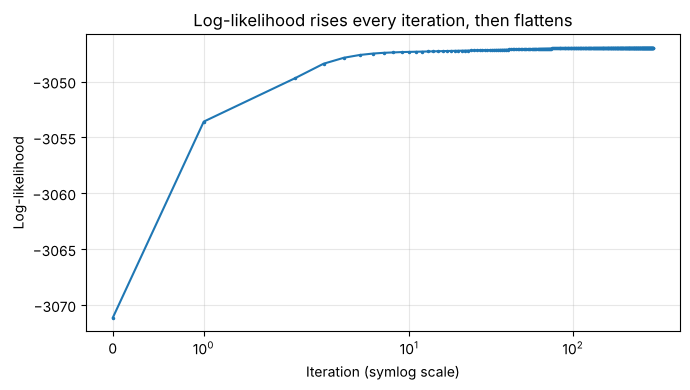

In [6]:
# Proof that the stopping rule works on the log-likelihood
changes = history["Log-Likelihood"].diff().dropna()
print("Did the log-likelihood ever go down?", bool((changes < -1e-9).any()))
print(f"Gain in iteration 1: {changes.iloc[0]:.4f}   Gain in the last iteration: {changes.iloc[-1]:.2e}")

plt.figure(figsize=(7, 4))
plt.plot(history["Iteration"], history["Log-Likelihood"], marker=".", ms=3)
plt.xscale("symlog"); plt.grid(alpha=0.3)
plt.xlabel("Iteration (symlog scale)"); plt.ylabel("Log-likelihood")
plt.title("Log-likelihood rises every iteration, then flattens")
save_and_show("part1_em_log_likelihood.png")

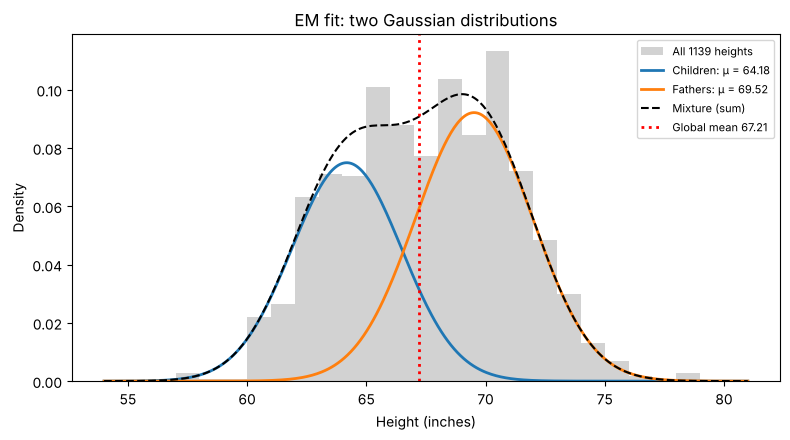

In [7]:
grid = np.linspace(heights.min() - 2, heights.max() + 2, 400)
plt.figure(figsize=(8, 4.5))
plt.hist(heights, bins=np.arange(np.floor(heights.min()), np.ceil(heights.max()) + 1), density=True,
         alpha=0.35, color="gray", label="All 1139 heights")
for k, color in enumerate(("tab:blue", "tab:orange")):
    plt.plot(grid, params["pi"][k] * gaussian_pdf(grid, params["mu"][k], params["var"][k]), color=color,
             lw=2, label=f"{LABELS[k]}: μ = {params['mu'][k]:.2f}")
plt.plot(grid, weighted_densities(grid, params).sum(axis=1), "k--", lw=1.5, label="Mixture (sum)")
plt.axvline(heights.mean(), color="red", ls=":", lw=2, label=f"Global mean {heights.mean():.2f}")
plt.xlabel("Height (inches)"); plt.ylabel("Density"); plt.title("EM fit: two Gaussian distributions")
plt.legend(fontsize=8)
save_and_show("part1_em_fit.png")

## 5. Should we just draw a line at the global mean and average each pile?

In [8]:
def posterior_for_height(height, params):
    # P(Children | h), P(Fathers | h): the E-step applied to one height
    r = e_step(np.array([float(height)]), params)[0]
    return r[0], r[1]


cut, low, high = global_mean_split(heights)
print(f"Global mean cut = {cut:.4f} in")
print(f"  Mean-split piles: means {low.mean():.4f} / {high.mean():.4f}, sd {low.std():.4f} / {high.std():.4f}")
print(f"  EM estimates:     means {params['mu'][0]:.4f} / {params['mu'][1]:.4f}, "
      f"sd {np.sqrt(params['var'][0]):.4f} / {np.sqrt(params['var'][1]):.4f}")

is_father, below = groups == "father", heights < cut
print(f"\nReal fathers put in the low 'Children' pile:  {np.sum(below & is_father)} of {np.sum(is_father)}")
print(f"Real children put in the high 'Fathers' pile: {np.sum(~below & ~is_father)} of {np.sum(~is_father)}")

fine_grid = np.linspace(60, 70, 100001)
boundary = fine_grid[np.argmin(np.abs(e_step(fine_grid, params)[:, 0] - 0.5))]
print(f"\nEM's 50/50 boundary: {boundary:.2f} in  (the mean split uses {cut:.2f} in)")
for h in (cut - 0.5, cut, cut + 0.5):
    p1, p2 = posterior_for_height(h, params)
    print(f"  {h:.2f} in: mean split says 100% {LABELS[0] if h < cut else LABELS[1]}; "
          f"EM says P(Children) = {p1:.3f}, P(Fathers) = {p2:.3f}")

Global mean cut = 67.2085 in
  Mean-split piles: means 64.2598 / 70.2147, sd 2.0354 / 1.8897
  EM estimates:     means 64.1772 / 69.5186, sd 2.3027 / 2.4578

Real fathers put in the low 'Children' pile:  44 of 205
Real children put in the high 'Fathers' pile: 403 of 934

EM's 50/50 boundary: 66.54 in  (the mean split uses 67.21 in)
  66.71 in: mean split says 100% Children; EM says P(Children) = 0.461, P(Fathers) = 0.539
  67.21 in: mean split says 100% Fathers; EM says P(Children) = 0.347, P(Fathers) = 0.653
  67.71 in: mean split says 100% Fathers; EM says P(Children) = 0.248, P(Fathers) = 0.752


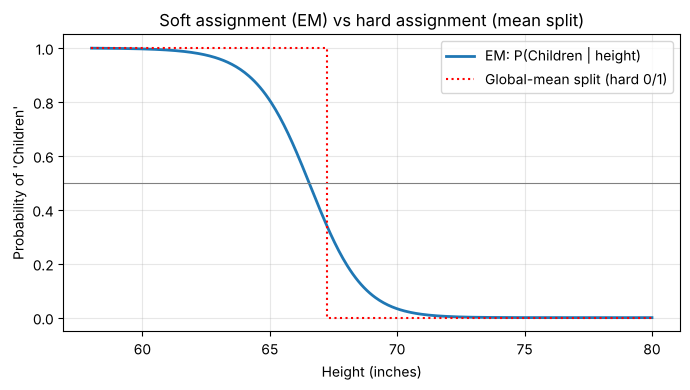

In [9]:
grid = np.linspace(58, 80, 400)
plt.figure(figsize=(7, 4))
plt.plot(grid, e_step(grid, params)[:, 0], lw=2, label="EM: P(Children | height)")
plt.step(grid, (grid < cut).astype(float), where="mid", color="red", ls=":", label="Global-mean split (hard 0/1)")
plt.axhline(0.5, color="gray", lw=0.8); plt.grid(alpha=0.3); plt.legend()
plt.xlabel("Height (inches)"); plt.ylabel("Probability of 'Children'")
plt.title("Soft assignment (EM) vs hard assignment (mean split)")
save_and_show("part1_em_posterior.png")

**Answer: No — we should not split at the global mean.** Evidence from the output above:

1. **Misclassification.** The cut at 67.21 in puts **44 of the 205 fathers** in the "Children" pile and **403 of the 934 children** in the "Fathers" pile. The two bell curves overlap, so no single line can separate them.
2. **Biased estimates.** The cut chops off each curve's tail, so the piles look narrower than they are: standard deviations 2.04 / 1.89 in vs EM's 2.30 / 2.46 in.
3. **Wrong boundary.** The global mean depends on how many people are in each group. EM's 50/50 point is **66.54 in**, not 67.21 in.
4. **No uncertainty.** A 66.71-in person is "100% child" for the cut; EM says 46.1% child / 53.9% father — almost a coin flip, and EM says so honestly. This is the benefit of soft assignments.
5. **No improvement.** The split is a one-time guess. EM starts from it and raises the log-likelihood from −3071.12 to −3046.99.

## 6. What did EM actually find? (checked with the hidden labels)

In [10]:
r = e_step(heights, params)
rows = []
for k, label in enumerate(LABELS):
    row = {"Component": label, "Effective size N_k": r[:, k].sum()}
    for g in ("daughter", "son", "father"):
        row[g + "s"] = r[groups == g, k].sum()
    row["% children"] = 100 * (row["daughters"] + row["sons"]) / row["Effective size N_k"]
    rows.append(row)
display(pd.DataFrame(rows).round(1).style.hide(axis="index"))

Component,Effective size N_k,daughters,sons,fathers,% children
Children,492.600000,357.900000,95.900000,38.800000,92.100000
Fathers,646.400000,95.100000,385.100000,166.200000,74.300000


* The **Children** component is **92% children** (mostly daughters, mean 64.2 in).
* The **Fathers** component holds **81% of all fathers** (166 of 205), but most of its weight is **sons**.

Why: Galton's "children" are **adults**. Sons (mean 69.2 in) are as tall as fathers (69.3 in). EM is unsupervised — it finds the two bell curves that best explain the numbers, and the strongest structure in these heights is sex, not generation. So a short height is confidently a child; a tall height means "father *or* adult son".

## 7. Live demo — classify the coach's test height

Type the coach's height into `TEST_HEIGHT` and run the cell. Every intermediate number is printed.

In [11]:
def explain_height(height, params):
    h = float(height)
    print(f"Test height h = {h} inches\n")
    parts = []
    for k, label in enumerate(LABELS):
        mu, var, pi = params["mu"][k], params["var"][k], params["pi"][k]
        density = gaussian_pdf(h, mu, var)
        parts.append(pi * density)
        print(f"{label:8s}: μ = {mu:.4f}, σ² = {var:.4f}, π = {pi:.4f}  ->  N(h) = {density:.6f},  π·N(h) = {pi * density:.6f}")
    total = sum(parts)
    print(f"\nEvidence P(h) = {parts[0]:.6f} + {parts[1]:.6f} = {total:.6f}\n")
    for k, label in enumerate(LABELS):
        print(f"P({label} | h = {h}) = {parts[k]:.6f} / {total:.6f} = {parts[k] / total:.4f}  ({100 * parts[k] / total:.2f}%)")


TEST_HEIGHT = 70.0   # <-- type the coach's height here (inches)
explain_height(TEST_HEIGHT, params)

Test height h = 70.0 inches

Children: μ = 64.1772, σ² = 5.3024, π = 0.4325  ->  N(h) = 0.007083,  π·N(h) = 0.003063
Fathers : μ = 69.5186, σ² = 6.0410, π = 0.5675  ->  N(h) = 0.159230,  π·N(h) = 0.090365

Evidence P(h) = 0.003063 + 0.090365 = 0.093428

P(Children | h = 70.0) = 0.003063 / 0.093428 = 0.0328  (3.28%)
P(Fathers | h = 70.0) = 0.090365 / 0.093428 = 0.9672  (96.72%)
